# 34.2 Image Representation

## Pixel

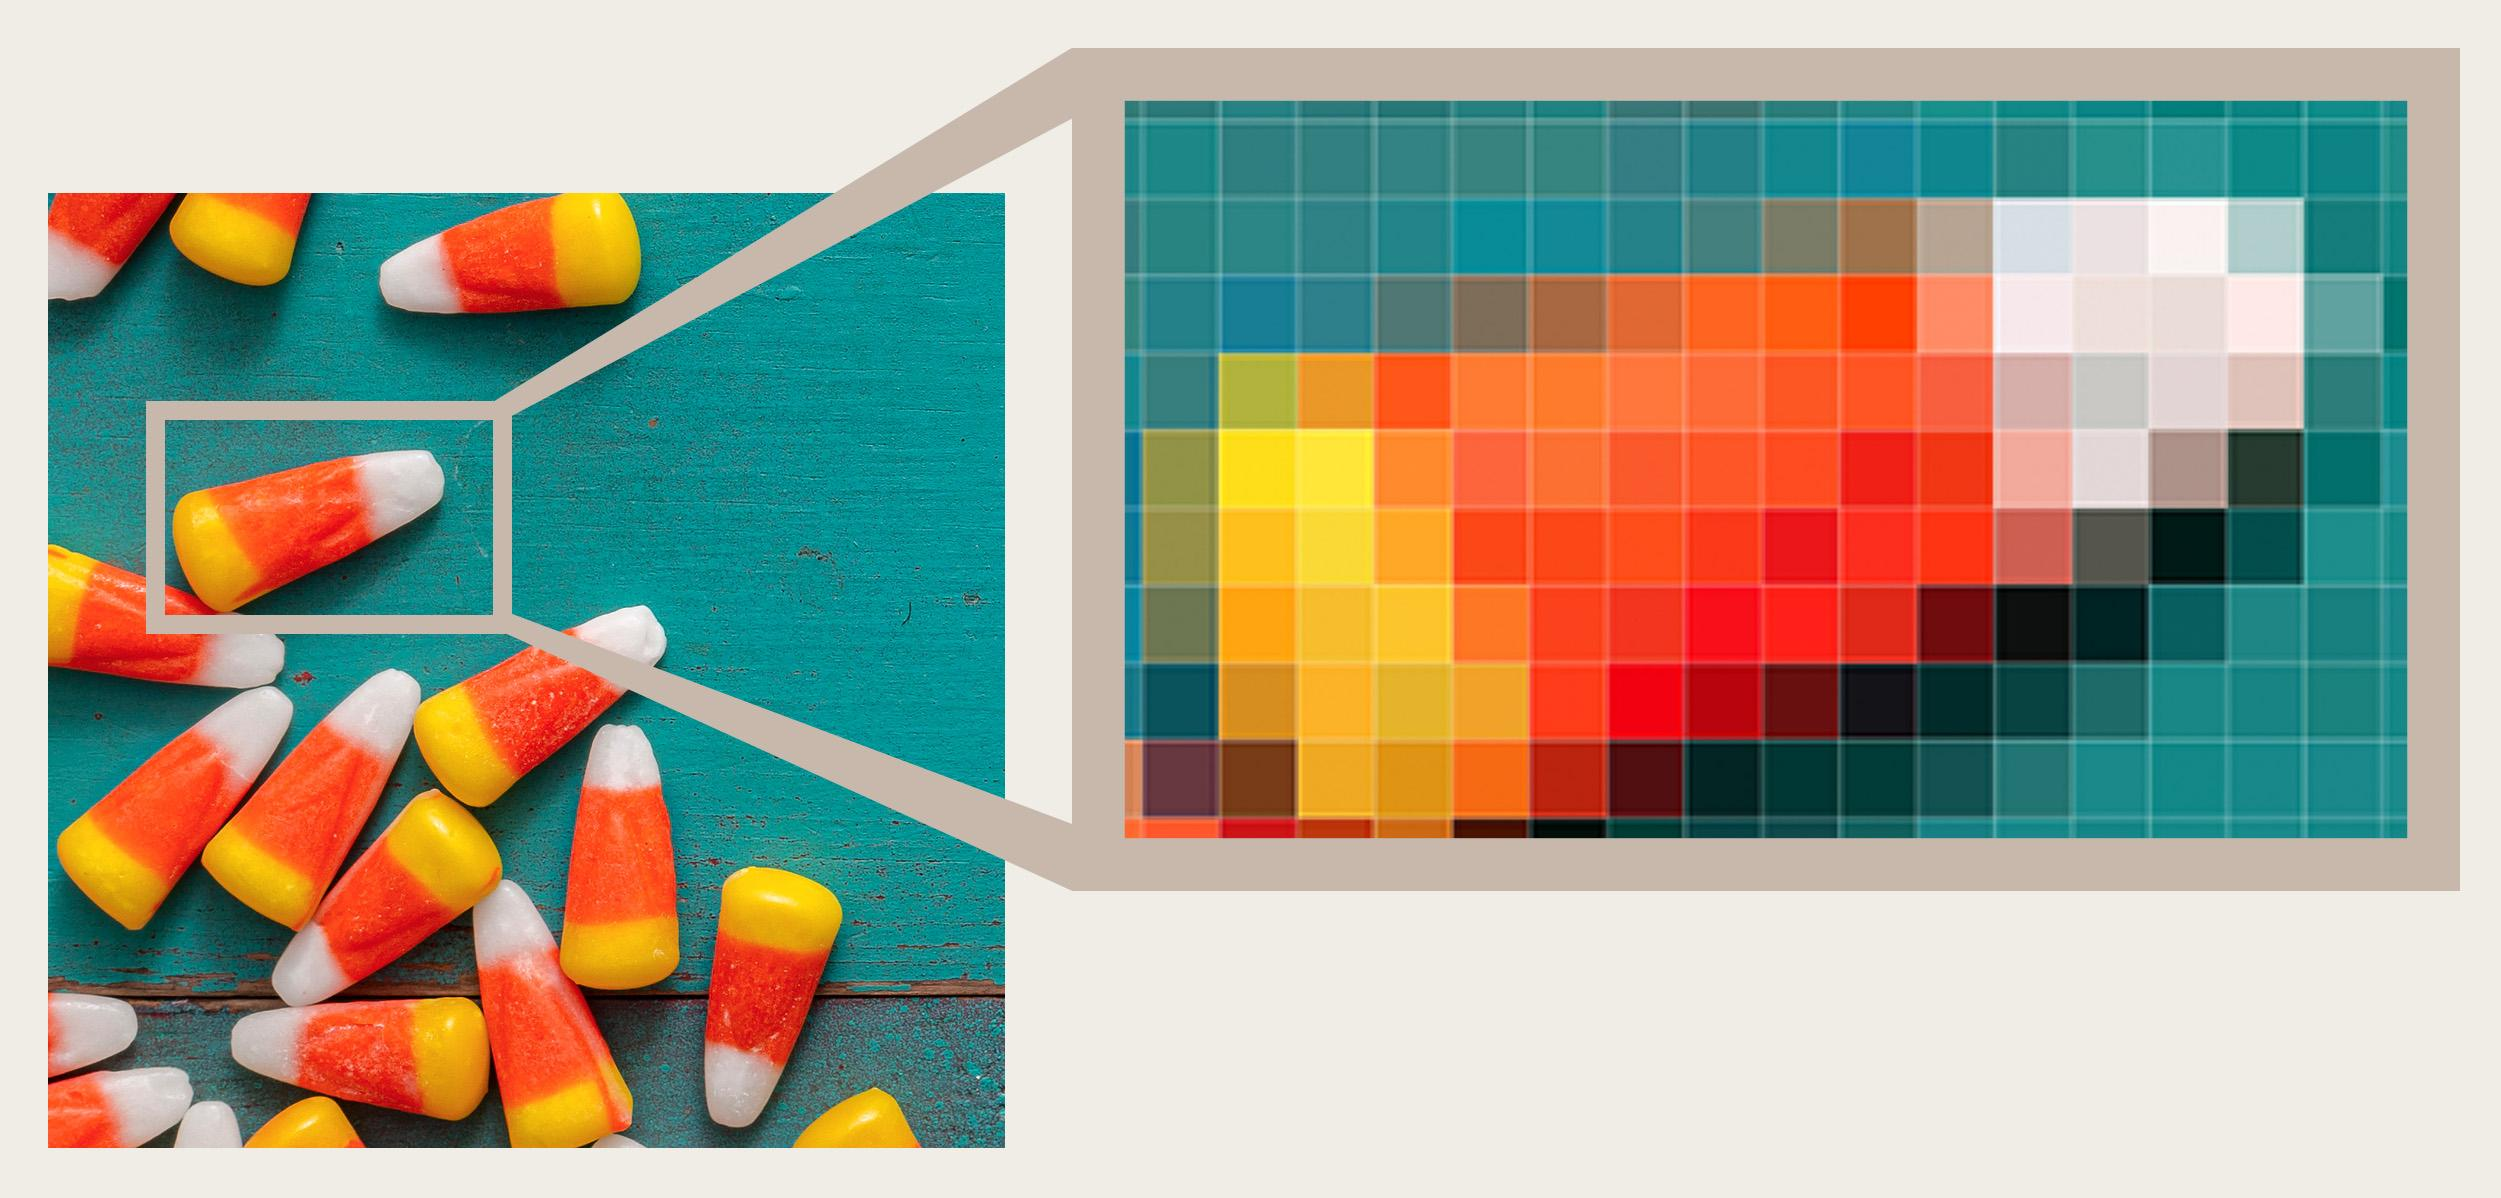

- A **pixel (picture element)** is the smallest spatial element of a digital image.
- Each pixel stores numerical information describing the image at that location.
- The number of values stored per pixel depends on the image representation.

For example:

- Grayscale pixel → one value
- RGB pixel → three values
- RGBA pixel → four values

---

## Height and Width

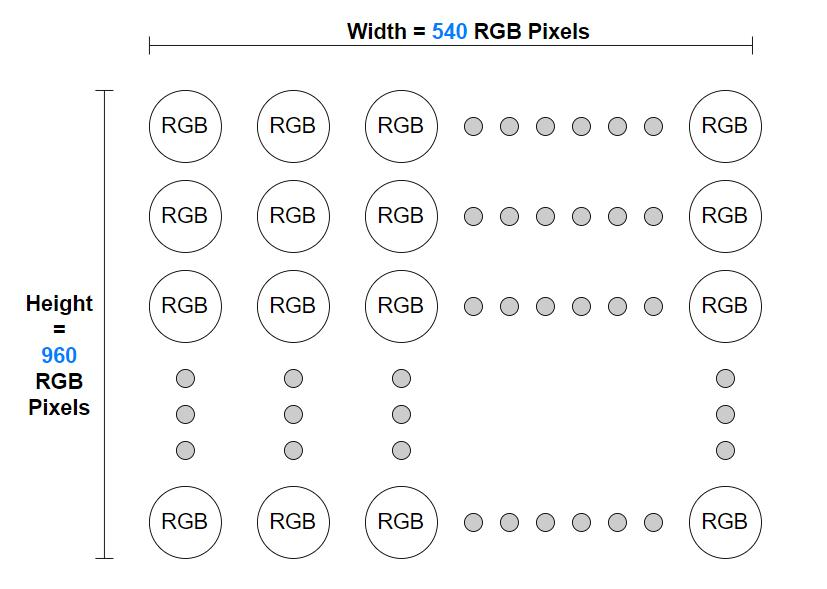

An image has two spatial dimensions:

- **Height ($H$)** → number of rows of pixels
- **Width ($W$)** → number of columns of pixels

For an image of height 224 and width 224:

$$
H \times W = 224 \times 224
$$

Number of spatial pixel locations:

$$
224 \times 224 = 50,176
$$

---

## Channels

A **channel** represents one component of the information stored for each pixel.

Common examples:

| Image type | Channels |
|---|---:|
| Grayscale | 1 |
| RGB | 3 |
| RGBA | 4 |

For an RGB image:

$$
\text{Image shape} = H \times W \times 3
$$

Each pixel is represented as:

$$
[R,G,B]
$$

---

## Grayscale

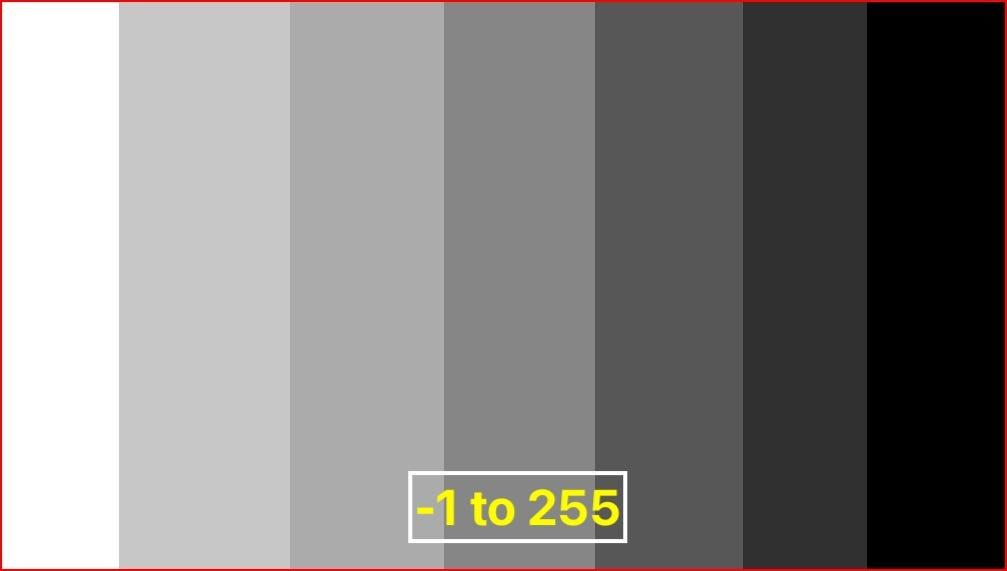

A grayscale image contains **one channel** representing intensity.

For a typical 8-bit grayscale image:

$$
0 \rightarrow \text{Black}
$$

$$
255 \rightarrow \text{White}
$$

Intermediate values represent shades of gray.

Example:

```text
0    → Black
50   → Dark gray
128  → Gray
200  → Light gray
255  → White
```

A grayscale image can be represented as:

$$
H \times W
$$

or explicitly:

$$
H \times W \times 1
$$

---

## RGB

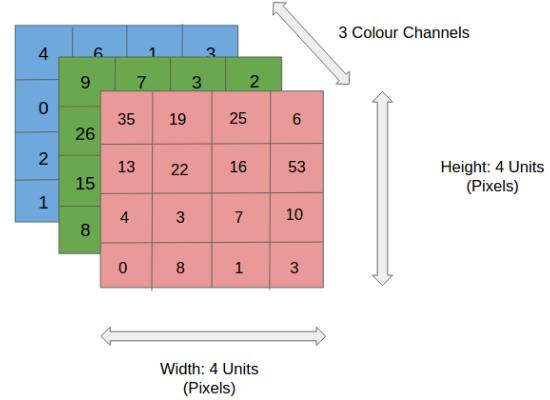
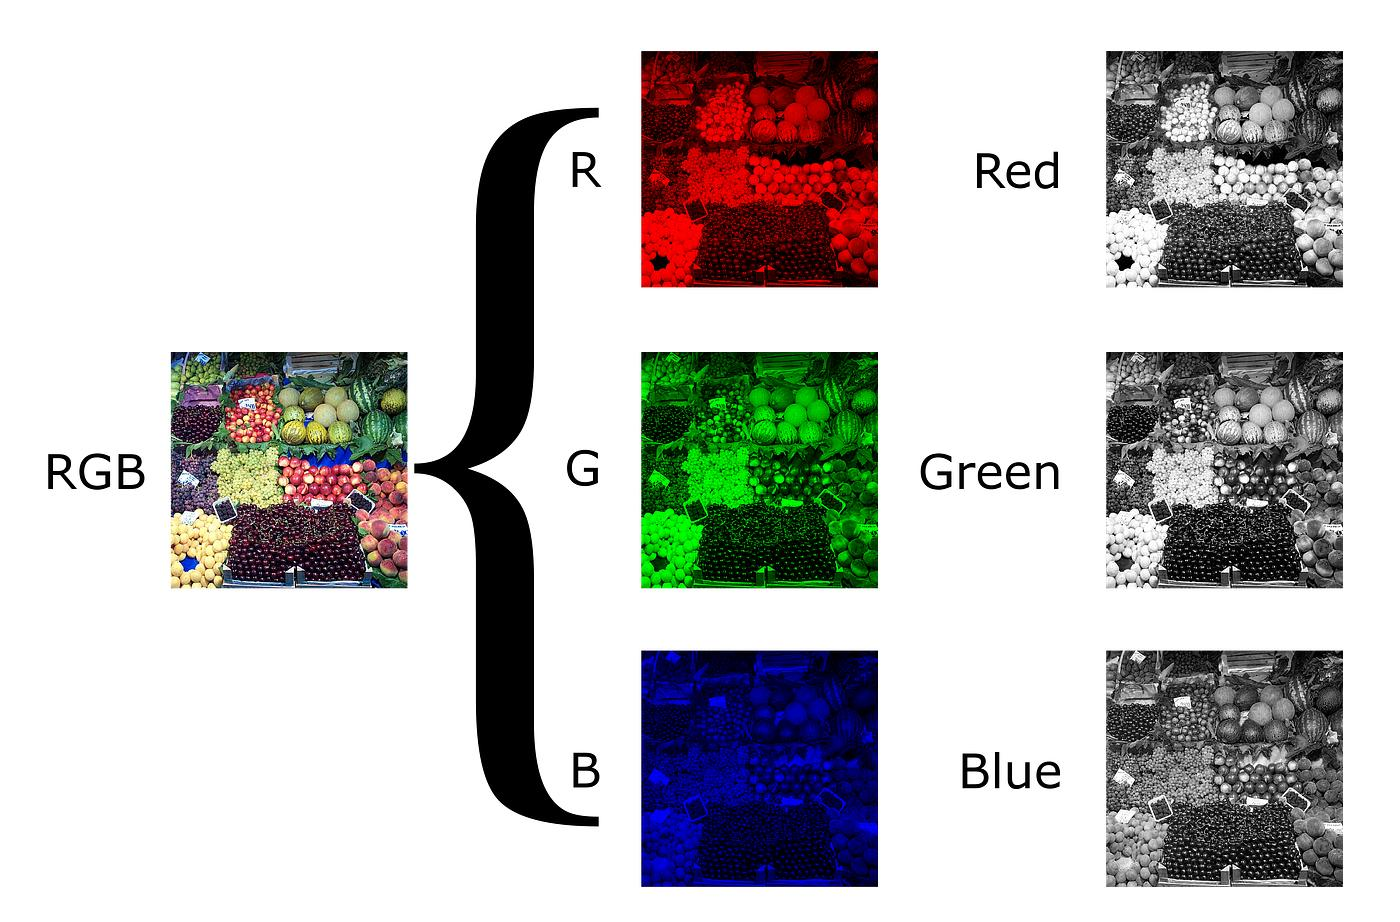

**RGB = Red + Green + Blue**

An RGB pixel contains three values:

$$
Pixel = [R,G,B]
$$

For a typical 8-bit RGB image:

$$
R,G,B \in [0,255]
$$

Examples:

```text
[255, 0, 0]       → Red
[0, 255, 0]       → Green
[0, 0, 255]       → Blue
[0, 0, 0]         → Black
[255,255,255]     → White
```

An RGB image has:

$$
\boxed{H \times W \times 3}
$$

For a 224 × 224 RGB image:

$$
224 \times 224 \times 3 = 150,528
$$

numerical values.

---

## RGBA

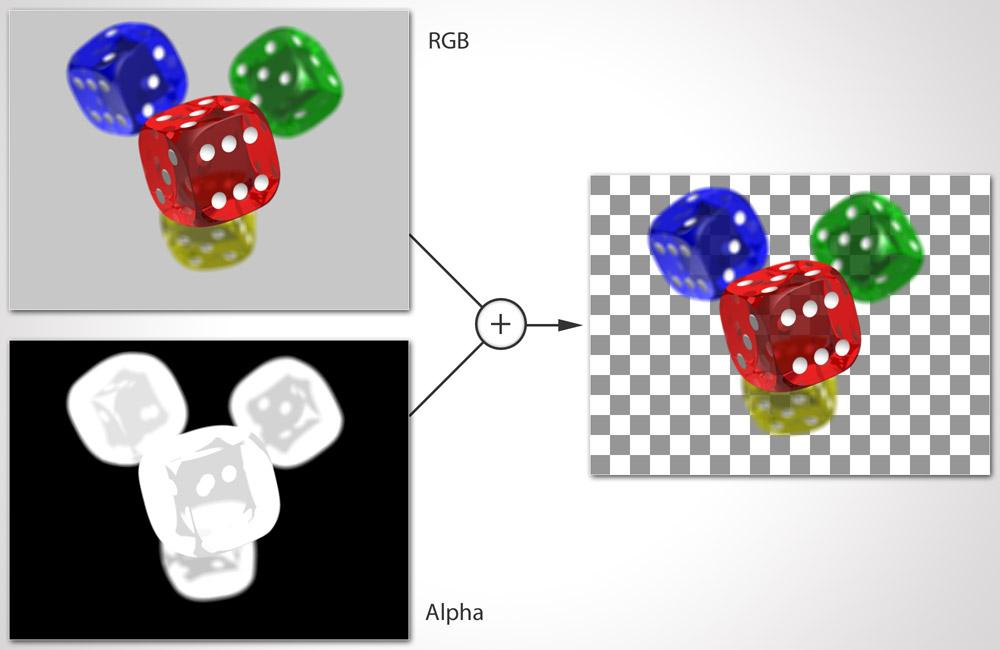

**RGBA = Red + Green + Blue + Alpha**

The additional **Alpha (A)** channel commonly represents transparency/opacity.

```text
R → Red
G → Green
B → Blue
A → Alpha
```

Therefore:

$$
\boxed{RGBA = H \times W \times 4}
$$

Example:

```text
[R, G, B, A]
```

> **Important:** Alpha is not another color channel; it provides transparency/opacity information.

---

## Color Spaces

A **color space** defines how colors are represented numerically.

Common color spaces include:

- **RGB**
- **HSV**
- **HSL**
- **YCbCr**
- **Lab**

### RGB

Represents color using:

$$
(R,G,B)
$$

### HSV

Represents color using:

- **H** → Hue
- **S** → Saturation
- **V** → Value

Different color spaces can make particular image-processing tasks easier.

> Changing a color space changes the **representation** of the color information; it does not inherently create additional visual information.

---

## Image Tensors

Deep-learning models process images as **tensors**.

A tensor is a multidimensional numerical array.

For an RGB image:

$$
H \times W \times C
$$

where:

- $H$ = height
- $W$ = width
- $C$ = channels

Example:

$$
224 \times 224 \times 3
$$

### Channel-Last

$$
\boxed{H \times W \times C}
$$

Example:

```text
224 × 224 × 3
```

### Channel-First

$$
\boxed{C \times H \times W}
$$

Example:

```text
3 × 224 × 224
```

PyTorch vision workflows commonly use **channel-first** tensors.

> The two representations contain the same image information; only the dimension ordering differs.

---

## Batch Dimension

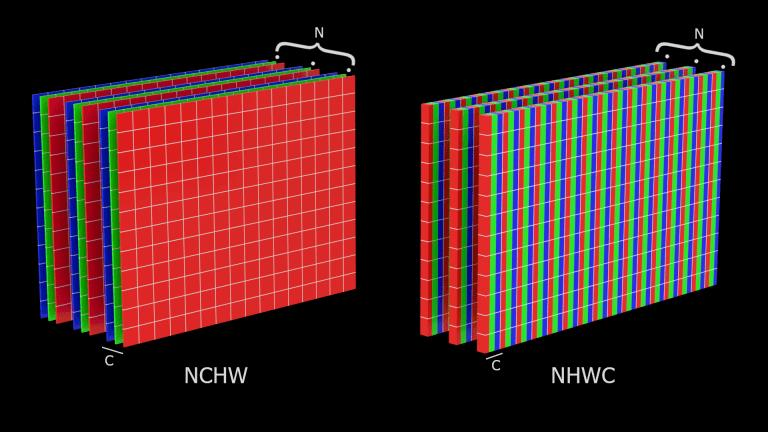

Deep-learning models usually process multiple images together.

For one RGB image in PyTorch:

$$
C \times H \times W
$$

Example:

```text
3 × 224 × 224
```

For a batch of 32 images:

$$
\boxed{B \times C \times H \times W}
$$

Therefore:

```text
32 × 3 × 224 × 224
```

where:

- $B$ = batch size
- $C$ = channels
- $H$ = height
- $W$ = width

### PyTorch Example

```python
import torch

image = torch.randn(3, 224, 224)

print(image.shape)
# torch.Size([3, 224, 224])

batch = image.unsqueeze(0)

print(batch.shape)
# torch.Size([1, 3, 224, 224])
```

`unsqueeze(0)` adds the batch dimension.

---

## Data Types

Image tensors can use different numerical data types.

Common types:

- `uint8`
- `float32`
- `float16`
- `bfloat16`

### `uint8`

Common for ordinary 8-bit images.

Range:

$$
0 \rightarrow 255
$$

### `float32`

Commonly used for deep-learning computation.

Pixel values can be represented using floating-point numbers such as:

```text
0.0
0.5
1.0
```

### Why does dtype matter?

It affects:

- Memory usage
- Numerical precision
- Computation
- GPU performance
- Compatibility with model operations

A typical workflow is:

```text
Image
  ↓
uint8
  ↓
float32
  ↓
Normalization
  ↓
Model
```

---

## Normalization

Normalization transforms image values into a numerical scale/distribution suitable for model processing.

A common scaling operation for 8-bit images is:

$$
x' = \frac{x}{255}
$$

Therefore:

$$
[0,255] \rightarrow [0,1]
$$

Examples:

```text
0   → 0.0
128 → 0.502...
255 → 1.0
```

### Standardization

Another common transformation is:

$$
x' = \frac{x-\mu}{\sigma}
$$

where:

- $\mu$ = mean
- $\sigma$ = standard deviation

> **Important:** Normalization is not always simply `x / 255`. Pretrained models may require specific preprocessing, including particular mean and standard deviation values.

---

# Complete Image Representation

Consider a 224 × 224 RGB image.

### Image dimensions

$$
H=224,\quad W=224,\quad C=3
$$

### Channel-last representation

$$
224 \times 224 \times 3
$$

### PyTorch channel-first representation

$$
3 \times 224 \times 224
$$

### Batch of 32 images

$$
\boxed{32 \times 3 \times 224 \times 224}
$$

The complete pipeline is:

```text
Image
  ↓
Pixels
  ↓
Height × Width × Channels
  ↓
Tensor
  ↓
Data Type
  ↓
Normalization
  ↓
Batch Dimension
  ↓
B × C × H × W
  ↓
Vision Model
```

---

# Key Shape Notation

| Notation | Meaning |
|---|---|
| $H \times W$ | Grayscale spatial dimensions |
| $H \times W \times 1$ | Grayscale with explicit channel |
| $H \times W \times 3$ | RGB, channel-last |
| $H \times W \times 4$ | RGBA, channel-last |
| $C \times H \times W$ | Single image, channel-first |
| $B \times C \times H \times W$ | Batch of images |

---

# Must Know 🔴

- Pixel
- Height and width
- Channels
- Grayscale
- RGB
- RGBA
- Color-space concept
- Image tensors
- Channel-first vs channel-last
- Batch dimension
- `B × C × H × W`
- `uint8` vs floating-point tensors
- Normalization

# Good to Know 🟡

- HSV
- HSL
- YCbCr
- Lab
- Why different color spaces are useful
- Memory implications of different data types

# Interview Points 🎯

### RGB image shape?

$$
H \times W \times 3
$$

or channel-first:

$$
3 \times H \times W
$$

### PyTorch batch shape?

$$
\boxed{B \times C \times H \times W}
$$

### What does `32 × 3 × 224 × 224` mean?

> 32 RGB images, each with height 224 and width 224.

### RGB vs RGBA?

> RGB has three color channels; RGBA adds an alpha channel commonly used for transparency/opacity.

### Why normalize?

> To put inputs into an appropriate numerical scale/distribution for model processing and optimization.

### Is `x / 255` always normalization?

> No. It is one common scaling operation. Model-specific preprocessing may additionally require mean/std normalization.

---

# Final Mental Model

$$
\boxed{
\text{Image}
\rightarrow
\text{Pixels}
\rightarrow
\text{Channels}
\rightarrow
\text{Tensor}
\rightarrow
\text{dtype}
\rightarrow
\text{Normalization}
\rightarrow
B\times C\times H\times W
}
$$

**Most important PyTorch CV shape:**

$$
\boxed{B \times C \times H \times W}
$$